In [1]:
from glob import glob 
import matplotlib.pyplot as plt
import numpy as np
import os
from PIL import Image
from keras_preprocessing.image import image_data_generator,img_to_array,load_img
from numpy import asarray
from keras.models import Model,Sequential,load_model
from keras.layers import Dense,Dropout,Input,ReLU
from tensorflow.keras.optimizers import Adam
from tqdm import tqdm
import cv2
from PIL import Image

In [2]:
train_path  = '/content/drive/MyDrive/MURA ELBOW SON/TRAİN/XR_ELBOW'
 

In [3]:
veri = []
boyut = 64
for dirname, _, filenames in os.walk(train_path):
  for filename in filenames:
    fullpath = os.path.join(dirname, filename)
    resim = cv2.imread(fullpath, cv2.IMREAD_GRAYSCALE)
    if(resim is not None):
      resim = cv2.resize(resim,(64,64))
      #resim = cv2.cvtColor(resim, cv2.COLOR_BGR2RGB)
      veri.append([resim])
          
          

In [ ]:
for i in veri:
  print(np.shape(i))

In [5]:
np.shape(veri)

(860, 1, 64, 64)

In [6]:
veri = np.array(veri).reshape(-1,64,64).astype('float32')

In [7]:
veri.shape

(860, 64, 64)

In [ ]:
for img in veri:
  print(img.shape)

In [9]:
 veri = (veri.astype(np.float32)-127.5)/127.5
 veri = veri.reshape(veri.shape[0],veri.shape[1]*veri.shape[2])

In [10]:
veri.shape

(860, 4096)

In [11]:
def create_generator():
  generator = Sequential()
  
  generator.add(Dense(units = 512, input_dim = 100))
  generator.add(ReLU())


  generator.add(Dense(units = 1024))
  generator.add(ReLU())

  generator.add(Dense(units = 64*64,activation = "tanh"))


  generator.compile(loss = "binary_crossentropy", optimizer = Adam(lr = 0.0001,beta_1 = 0.5))

  return generator

In [12]:
g = create_generator()
g.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 512)               51712     
                                                                 
 re_lu (ReLU)                (None, 512)               0         
                                                                 
 dense_1 (Dense)             (None, 1024)              525312    
                                                                 
 re_lu_1 (ReLU)              (None, 1024)              0         
                                                                 
 dense_2 (Dense)             (None, 4096)              4198400   
                                                                 
Total params: 4,775,424
Trainable params: 4,775,424
Non-trainable params: 0
_________________________________________________________________


In [17]:
def create_discriminator():
  discriminator = Sequential()
  
  discriminator.add(Dense(units = 1024, input_dim = 64*64 ))
  discriminator.add(ReLU())
  discriminator.add(Dropout(0.4))


  
  discriminator.add(Dense(units = 512))
  discriminator.add(ReLU())
  discriminator.add(Dropout(0.4))
  
  
  discriminator.add(Dense(units = 256))
  discriminator.add(ReLU())

  discriminator.add(Dense(units = 1,activation="sigmoid"))

  discriminator.compile(loss = "binary_crossentropy", optimizer = Adam(lr = 0.0001,beta_1 = 0.5) )

  return discriminator


In [18]:
d =  create_discriminator()
d.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_7 (Dense)             (None, 1024)              4195328   
                                                                 
 re_lu_5 (ReLU)              (None, 1024)              0         
                                                                 
 dropout_2 (Dropout)         (None, 1024)              0         
                                                                 
 dense_8 (Dense)             (None, 512)               524800    
                                                                 
 re_lu_6 (ReLU)              (None, 512)               0         
                                                                 
 dropout_3 (Dropout)         (None, 512)               0         
                                                                 
 dense_9 (Dense)             (None, 256)              

In [19]:
def create_gan(discriminator,generator):
  discriminator.trainable = False
  gan_input = Input(shape = (100, ) )

  x = generator(gan_input)
  gan_output = discriminator(x)

  gan = Model(inputs = gan_input, outputs = gan_output)

  gan.compile(loss = "binary_crossentropy", optimizer = "adam")
  return gan


In [20]:
gan = create_gan(d,g)
gan.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 100)]             0         
                                                                 
 sequential (Sequential)     (None, 4096)              4775424   
                                                                 
 sequential_2 (Sequential)   (None, 1)                 4851713   
                                                                 
Total params: 9,627,137
Trainable params: 4,775,424
Non-trainable params: 4,851,713
_________________________________________________________________


In [21]:
veri.shape[0]

860

In [22]:
epochs = 50
batch_size = 256

noise = np.random.normal(0,1, [batch_size,100])

generated_images = g.predict(noise)

image_batch = veri[np.random.randint(low= 0, high = veri.shape[0],size = batch_size)]

print(generated_images.shape)
print(image_batch.shape)

(256, 4096)
(256, 4096)


In [ ]:

epochs = 50
batch_size = 256


for e in range(epochs):
  for _ in range(batch_size):
    noise = np.random.normal(0,1, [batch_size,100])

    generated_images = g.predict(noise)

    image_batch = veri[np.random.randint(low= 0, high = veri.shape[0],size = batch_size)]

    x = np.concatenate([image_batch, generated_images])

    y_dis = np.zeros(batch_size*2)
    y_dis[:batch_size] = 1

    d.trainable = True
    d.train_on_batch(x,y_dis)

    noise = np.random.normal(0,1,[batch_size,100])

    y_gen = np.ones(batch_size)

    d.trainable = False
    gan.train_on_batch(noise,y_gen)
  print("epochs: ",e)

In [25]:
import keras
import tensorflow as tf
from keras.models import load_model
#g.save("gans_model2.h5")

g_load = load_model("/content/drive/MyDrive/MURA ELBOW SON/gans_model2.h5")

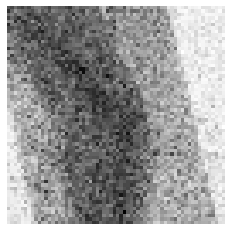

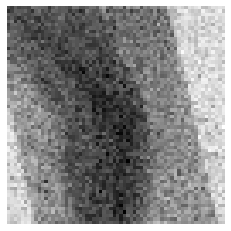

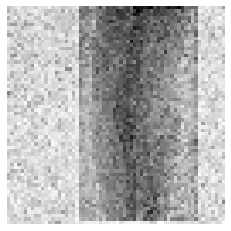

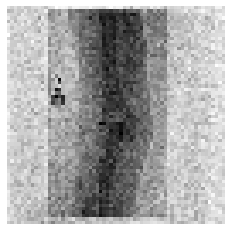

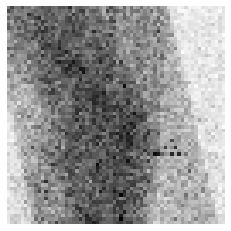

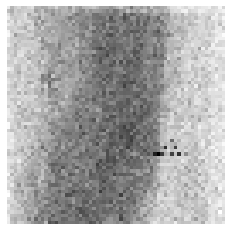

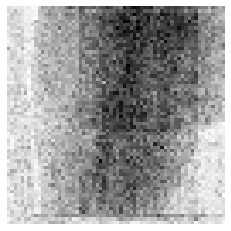

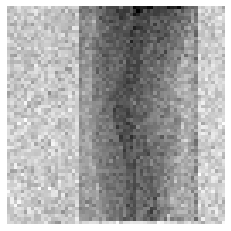

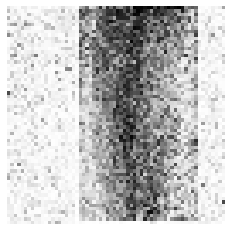

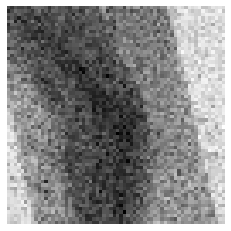

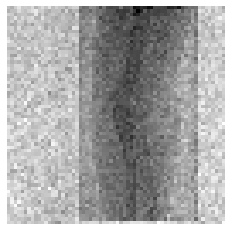

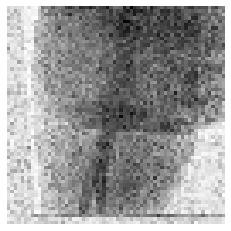

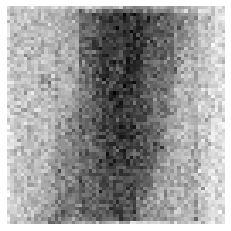

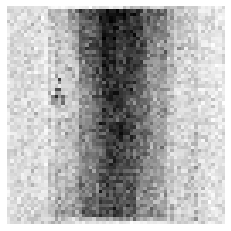

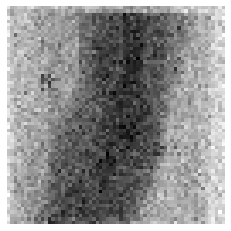

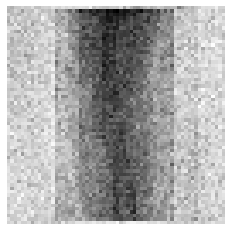

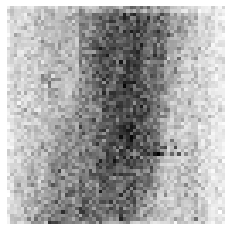

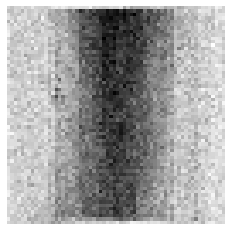

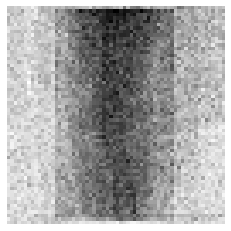

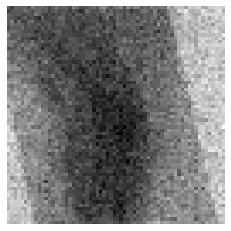

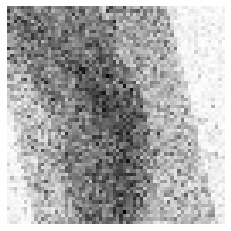

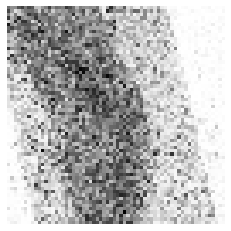

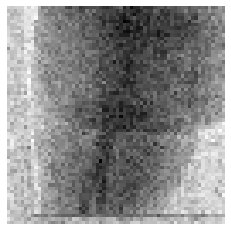

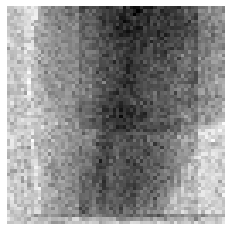

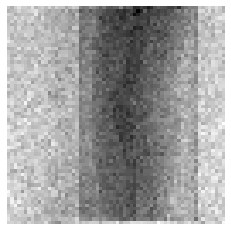

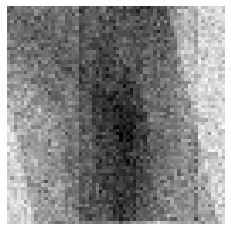

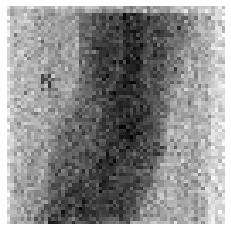

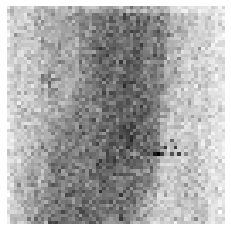

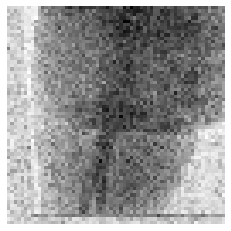

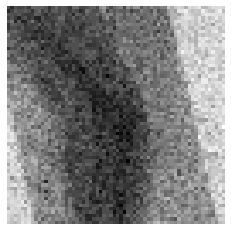

In [28]:
noise = np.random.normal(loc= 0, scale = 1,size=[100,100])
generated_images =  g_load.predict(noise)
generated_images = generated_images.reshape(100,64,64)

for i in range(0,30,1):
  plt.imshow(generated_images[i],cmap = "gray", interpolation = "nearest")
  plt.axis("off"),plt.show()

